<a href="https://colab.research.google.com/github/jinckzx/musicify/blob/master/melspecto_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi -L || echo "No GPU detected"
!pip -q install -U huggingface_hub kagglehub librosa soundfile

GPU 0: Tesla T4 (UUID: GPU-2fd14c08-6da4-482a-105b-73ce3af77a1d)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.


In [ ]:
import os, glob, json, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display
import torch
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ---------------- configuration (edit freely) ----------------
SEED         = 42
SR           = 16_000            # all models use 16 kHz mono
DUR          = 30                # GTZAN clips are 30 s
LEN          = SR * DUR
N_SEG        = 10                # 3-second segments per song for classical features
HF_REPO_NAME = "gtzan-genre-cnn" # repo is created under your own HF username
PRIVATE_REPO = False
SAVE_DIR     = "/content/gtzan-genre-cnn"
# -------------------------------------------------------------

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(SAVE_DIR, exist_ok=True)
print("device:", DEVICE, "|", torch.__version__, "| librosa", librosa.__version__)

device: cuda | 2.14.1+cu130 | librosa 1.0.1


In [ ]:
import kagglehub

try:
    root = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")
except Exception as e:
    raise RuntimeError(
        "Kaggle download failed. Add KAGGLE_USERNAME and KAGGLE_KEY as Colab secrets "
        "(or upload your kaggle.json) and re-run this cell."
    ) from e

cands = glob.glob(os.path.join(root, "**", "genres_original"), recursive=True)
assert cands, f"genres_original not found under {root}"
GENRES_DIR = cands[0]
print("audio folder:", GENRES_DIR)
print(sorted(os.listdir(GENRES_DIR)))

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
audio folder: /kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


In [ ]:
rows = []
for g in sorted(os.listdir(GENRES_DIR)):
    gdir = os.path.join(GENRES_DIR, g)
    if not os.path.isdir(gdir):
        continue
    for f in sorted(os.listdir(gdir)):
        if f.endswith(".wav"):
            rows.append(dict(path=os.path.join(gdir, f), genre=g, song=f[:-4]))

meta = pd.DataFrame(rows)
GENRES   = sorted(meta.genre.unique())
label2id = {g: i for i, g in enumerate(GENRES)}
id2label = {i: g for g, i in label2id.items()}
meta["label"] = meta.genre.map(label2id)

print(len(meta), "files |", len(GENRES), "genres")
meta.genre.value_counts().sort_index()

1000 files | 10 genres


,count
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100


In [ ]:
def load_wave(path):
    """Load -> mono -> 16 kHz -> exactly 30 s.  Handle the non readible files"""
    try:
        y, _ = librosa.load(path, sr=SR, mono=True, duration=DUR)
        if len(y) < LEN:
            y = np.pad(y, (0, LEN - len(y)))
        return y[:LEN].astype(np.float32)
    except Exception:
        return None

t0 = time.time()
waves = Parallel(n_jobs=-1, verbose=5)(delayed(load_wave)(p) for p in meta.path)

ok = np.array([w is not None for w in waves])
print("\nunreadable files dropped:", meta.loc[~ok, "song"].tolist())
meta = meta[ok].reset_index(drop=True)
WAVES  = np.stack([w for w in waves if w is not None]); del waves
LABELS = meta.label.values

print(f"WAVES {WAVES.shape}  ({WAVES.nbytes/1e9:.2f} GB)  loaded in {time.time()-t0:.0f}s")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:    7.3s
[Parallel(n_jobs=-1)]: Done 102 tasks      | elapsed:   11.6s
[Parallel(n_jobs=-1)]: Done 282 tasks      | elapsed:   18.7s
[Parallel(n_jobs=-1)]: Done 534 tasks      | elapsed:   26.1s
[Parallel(n_jobs=-1)]: Done 858 tasks      | elapsed:   36.7s
[Parallel(n_jobs=-1)]: Done 997 out of 1000 | elapsed:   41.1s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:   41.1s finished



unreadable files dropped: ['jazz.00054']
WAVES (999, 480000)  (1.92 GB)  loaded in 42s


**EDA one melspecttogram per genre**

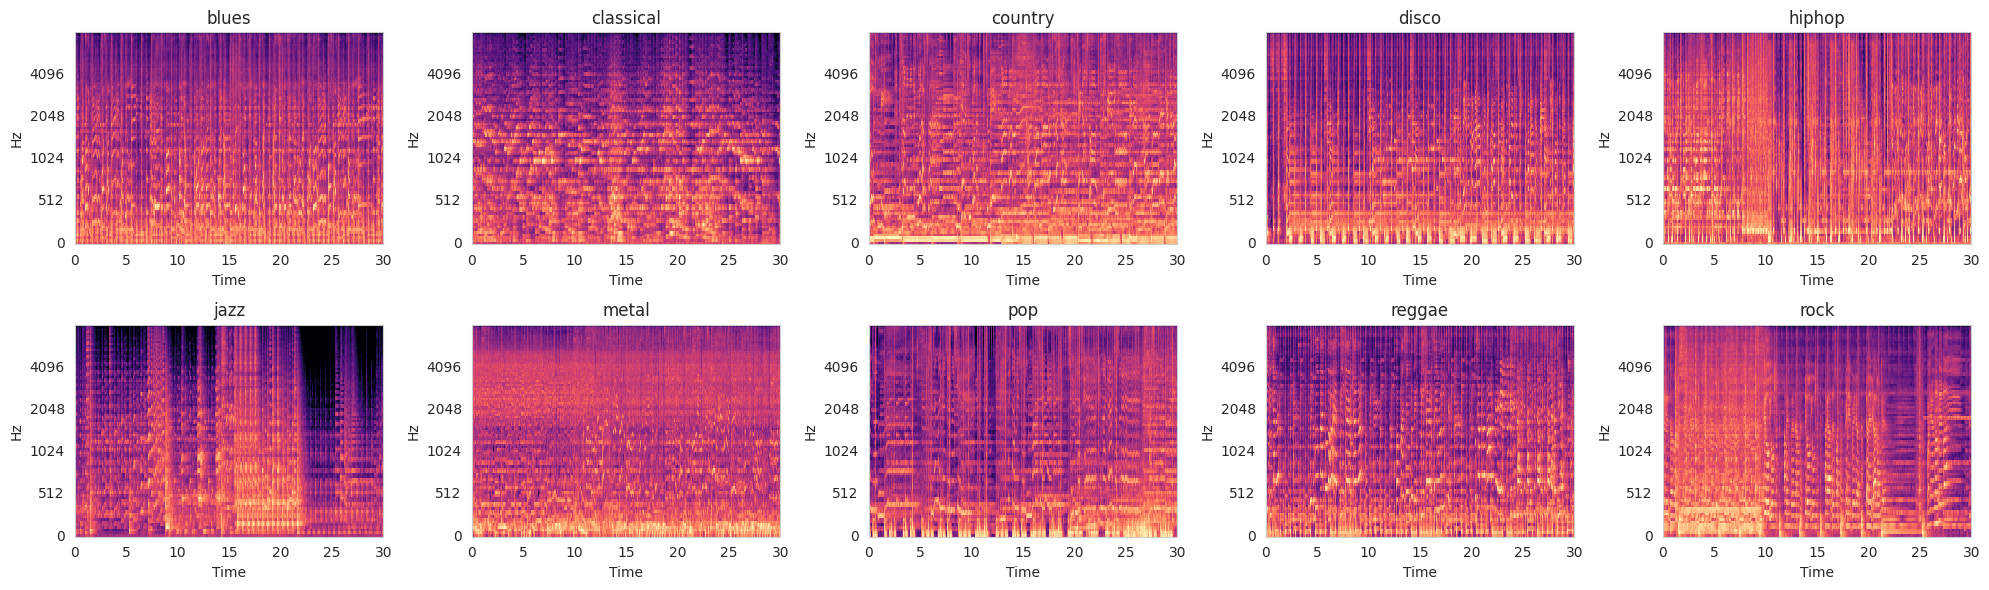

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 6))
for ax, g in zip(axes.ravel(), GENRES):
    i = meta.index[meta.genre == g][0]
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=WAVES[i], sr=SR, n_mels=96), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(g)
plt.tight_layout(); plt.show()

To maintain the same class distribution across training, validation, and test datasets, preventing class imbalance from being introduced by random splitting. Using stratify

In [ ]:
all_idx = np.arange(len(meta))
tr_idx, tmp_idx = train_test_split(all_idx, test_size=0.20, stratify=LABELS, random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=LABELS[tmp_idx], random_state=SEED)

assert not (set(tr_idx) & set(va_idx)) and not (set(tr_idx) & set(te_idx)) and not (set(va_idx) & set(te_idx))
print(f"train {len(tr_idx)} | val {len(va_idx)} | test {len(te_idx)} songs")

pd.DataFrame({"train": np.bincount(LABELS[tr_idx], minlength=len(GENRES)),
              "val":   np.bincount(LABELS[va_idx], minlength=len(GENRES)),
              "test":  np.bincount(LABELS[te_idx], minlength=len(GENRES))}, index=GENRES)

train 799 | val 100 | test 100 songs


,train,val,test
blues,80,10,10
classical,80,10,10
country,80,10,10
disco,80,10,10
hiphop,80,10,10
jazz,79,10,10
metal,80,10,10
pop,80,10,10
reggae,80,10,10
rock,80,10,10


Training: 80%



Validation: 10%



Testing: 10%

In [ ]:
_tempo = getattr(librosa.feature, "tempo", None) or librosa.beat.tempo

def seg_features(y, tempo):
    """Feature dict for one 3-second segment."""
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))
    f = {}
    def add(name, M):
        M = np.atleast_2d(M)
        for k in range(M.shape[0]):
            tag = name if M.shape[0] == 1 else f"{name}{k}"
            f[tag + "_mean"] = float(M[k].mean())
            f[tag + "_std"]  = float(M[k].std())
    add("mfcc",      librosa.feature.mfcc(y=y, sr=SR, n_mfcc=20))
    add("chroma",    librosa.feature.chroma_stft(S=S**2, sr=SR))
    add("centroid",  librosa.feature.spectral_centroid(S=S, sr=SR))
    add("bandwidth", librosa.feature.spectral_bandwidth(S=S, sr=SR))
    add("rolloff",   librosa.feature.spectral_rolloff(S=S, sr=SR))
    add("flatness",  librosa.feature.spectral_flatness(S=S))
    add("contrast",  librosa.feature.spectral_contrast(S=S, sr=SR, fmin=100.0, n_bands=6))
    add("zcr",       librosa.feature.zero_crossing_rate(y, frame_length=2048, hop_length=512))
    add("rms",       librosa.feature.rms(S=S))
    f["tempo"] = float(tempo)          # song-level, repeated for each segment
    return f

def song_feature_matrix(y):
    oenv  = librosa.onset.onset_strength(y=y, sr=SR)
    tempo = np.atleast_1d(_tempo(onset_envelope=oenv, sr=SR))[0]
    segs  = y.reshape(N_SEG, -1)                       # 10 x 3 s
    return np.array([list(seg_features(s, tempo).values()) for s in segs], dtype=np.float32)

FEATURE_NAMES = list(seg_features(WAVES[0][:SR * 3], 120.0).keys())
print(len(FEATURE_NAMES), "features per segment")

91 features per segment


In [ ]:
t0 = time.time()
FEATS = np.stack(Parallel(n_jobs=-1, verbose=5)(delayed(song_feature_matrix)(WAVES[i]) for i in range(len(WAVES))))
print(f"FEATS {FEATS.shape} (songs x segments x features) in {time.time()-t0:.0f}s")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:    4.1s
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:   15.4s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:   36.3s
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 878 tasks      | elapsed:  3.1min
[Parallel(n_jobs=-1)]: Done 999 out of 999 | elapsed:  3.5min finished


FEATS (999, 10, 91) (songs x segments x features) in 211s


random forests, extratrees, gradient boosting, svm classifiers comparision

In [ ]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

F = FEATS.shape[-1]
Xtr = FEATS[tr_idx].reshape(-1, F)
ytr = np.repeat(LABELS[tr_idx], N_SEG)

def song_proba(model, idx):
    """Average segment probabilities -> one probability vector per song."""
    p = model.predict_proba(FEATS[idx].reshape(-1, F))
    return p.reshape(len(idx), N_SEG, -1).mean(axis=1)

clf_zoo = {
    "Random Forest":     RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    "Extra Trees":       ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    "SVM (RBF)":         make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", probability=True, random_state=SEED)),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED),
}

clf_probs, rows = {}, []
for name, m in clf_zoo.items():
    t0 = time.time()
    m.fit(Xtr, ytr)
    pv, pt = song_proba(m, va_idx), song_proba(m, te_idx)
    clf_probs[name] = (pv, pt)
    rows.append(dict(model=name,
                     val_song_acc=accuracy_score(LABELS[va_idx], pv.argmax(1)),
                     test_song_acc=accuracy_score(LABELS[te_idx], pt.argmax(1)),
                     fit_seconds=round(time.time() - t0)))
    print(f"{name:18s} done")

classical_df = pd.DataFrame(rows).set_index("model")
BEST_CLF_NAME = classical_df.val_song_acc.idxmax()      # choose on VAL, never on test
print("\nbest classical model (by val):", BEST_CLF_NAME)
classical_df.style.format({"val_song_acc": "{:.1%}", "test_song_acc": "{:.1%}"})

Random Forest      done
Extra Trees        done
SVM (RBF)          done
Gradient Boosting  done

best classical model (by val): Random Forest


,val_song_acc,test_song_acc,fit_seconds
model,,,
Random Forest,83.0%,77.0%,24
Extra Trees,79.0%,75.0%,5
SVM (RBF),81.0%,86.0%,22
Gradient Boosting,81.0%,81.0%,43


What does random forests listen to ?

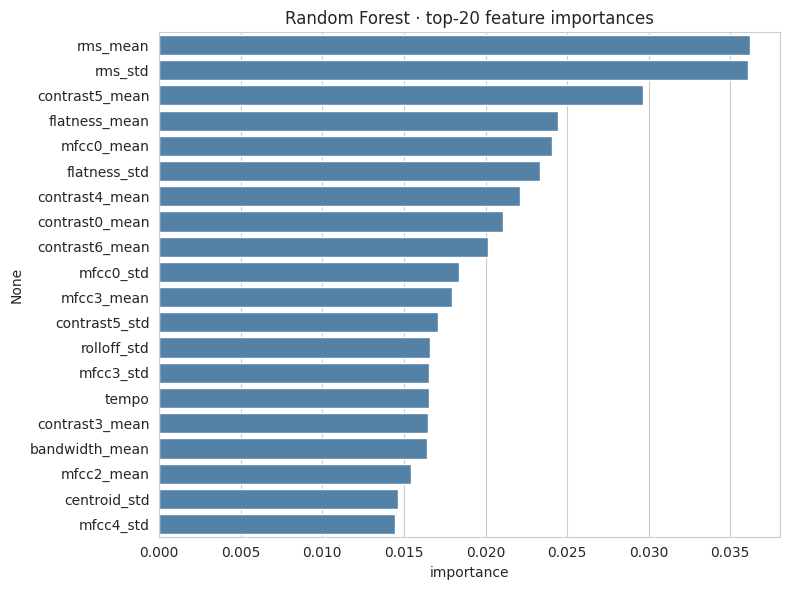

In [ ]:
rf = clf_zoo["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False).head(20)
plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Random Forest · top-20 feature importances"); plt.xlabel("importance"); plt.tight_layout(); plt.show()

**CNN on the melspectograms**

In [ ]:
MODEL_SRC = r"""
import numpy as np
import librosa
import torch
import torch.nn as nn
import torch.nn.functional as tnf
from huggingface_hub import PyTorchModelHubMixin

# ---- audio front-end: must be identical in training and inference ----
SR = 16000
N_FFT = 1024
HOP = 320              # 20 ms
N_MELS = 128
FMIN, FMAX = 20, 8000
DB_FLOOR = -80.0
CROP_FRAMES = 150      # 3.0 s

def logmel(y, sr=SR):
    S = librosa.feature.melspectrogram(y=np.asarray(y, dtype=np.float32), sr=sr, n_fft=N_FFT,
                                       hop_length=HOP, n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0)
    db = librosa.power_to_db(S, ref=1.0, amin=1e-10, top_db=None)
    return np.maximum(db, DB_FLOOR).astype(np.float32)          # [mels, frames]

def mel_windows(m, hop=CROP_FRAMES // 2):
    # m: [mels, frames] (already normalised) -> [n_windows, 1, mels, CROP_FRAMES]
    return m.unfold(1, CROP_FRAMES, hop).permute(1, 0, 2).unsqueeze(1).contiguous()

class ConvBlock(nn.Module):
    def __init__(self, cin, cout, p_drop):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(p_drop),
        )
    def forward(self, x):
        return self.net(x)

class GenreCNN(nn.Module, PyTorchModelHubMixin):
    def __init__(self, n_classes: int = 10, base_ch: int = 32, dropout: float = 0.4):
        super().__init__()
        c = [base_ch, base_ch * 2, base_ch * 4, base_ch * 8]
        self.features = nn.Sequential(
            ConvBlock(1, c[0], 0.05), ConvBlock(c[0], c[1], 0.10),
            ConvBlock(c[1], c[2], 0.15), ConvBlock(c[2], c[3], 0.20),
        )
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(c[3] * 2, n_classes))
    def forward(self, x):                       # x: [B, 1, mels, frames]
        h = self.features(x).mean(dim=2)        # average over frequency -> [B, C, T']
        h = torch.cat([h.mean(-1), h.amax(-1)], dim=1)   # time mean + time max
        return self.head(h)                     # logits

@torch.no_grad()
def predict_song(model, wave, mean, std, hop=CROP_FRAMES // 2, bs=256):
    # wave: 1-D float array, 16 kHz mono, any length >= ~1 s. Returns class probabilities.
    model.eval()
    dev = next(model.parameters()).device
    m = (torch.from_numpy(logmel(wave)) - mean) / std
    if m.shape[1] < CROP_FRAMES:
        m = tnf.pad(m, (0, CROP_FRAMES - m.shape[1]), value=(DB_FLOOR - mean) / std)
    x = mel_windows(m, hop)
    probs = [model(x[i:i + bs].to(dev)).float().softmax(-1).cpu() for i in range(0, len(x), bs)]
    return torch.cat(probs).mean(0).numpy()
"""
exec(MODEL_SRC)
print("model source loaded:", len(MODEL_SRC.splitlines()), "lines")

model source loaded: 63 lines


In [ ]:
# Precompute log-mels for every song once, normalise with TRAIN-ONLY statistics, keep on the GPU

t0 = time.time()
mels = Parallel(n_jobs=-1, verbose=5)(delayed(logmel)(WAVES[i]) for i in range(len(WAVES)))
MEL = np.stack(mels); del mels                                   # [songs, mels, frames]

MEAN, STD = float(MEL[tr_idx].mean()), float(MEL[tr_idx].std())
MEL_T = torch.from_numpy((MEL - MEAN) / STD).transpose(1, 2).contiguous().to(DEVICE)   # [songs, frames, mels]
N_FRAMES = MEL_T.shape[1]
del MEL

print(f"MEL_T {tuple(MEL_T.shape)} on {MEL_T.device} | train mean {MEAN:.1f} dB, std {STD:.1f} dB | {time.time()-t0:.0f}s")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  24 tasks      | elapsed:    0.9s
[Parallel(n_jobs=-1)]: Done 132 tasks      | elapsed:    5.6s
[Parallel(n_jobs=-1)]: Done 440 tasks      | elapsed:   12.6s
[Parallel(n_jobs=-1)]: Done 944 tasks      | elapsed:   23.9s
[Parallel(n_jobs=-1)]: Done 999 out of 999 | elapsed:   25.0s finished


MEL_T (999, 1501, 128) on cuda:0 | train mean -17.3 dB, std 15.5 dB | 28s


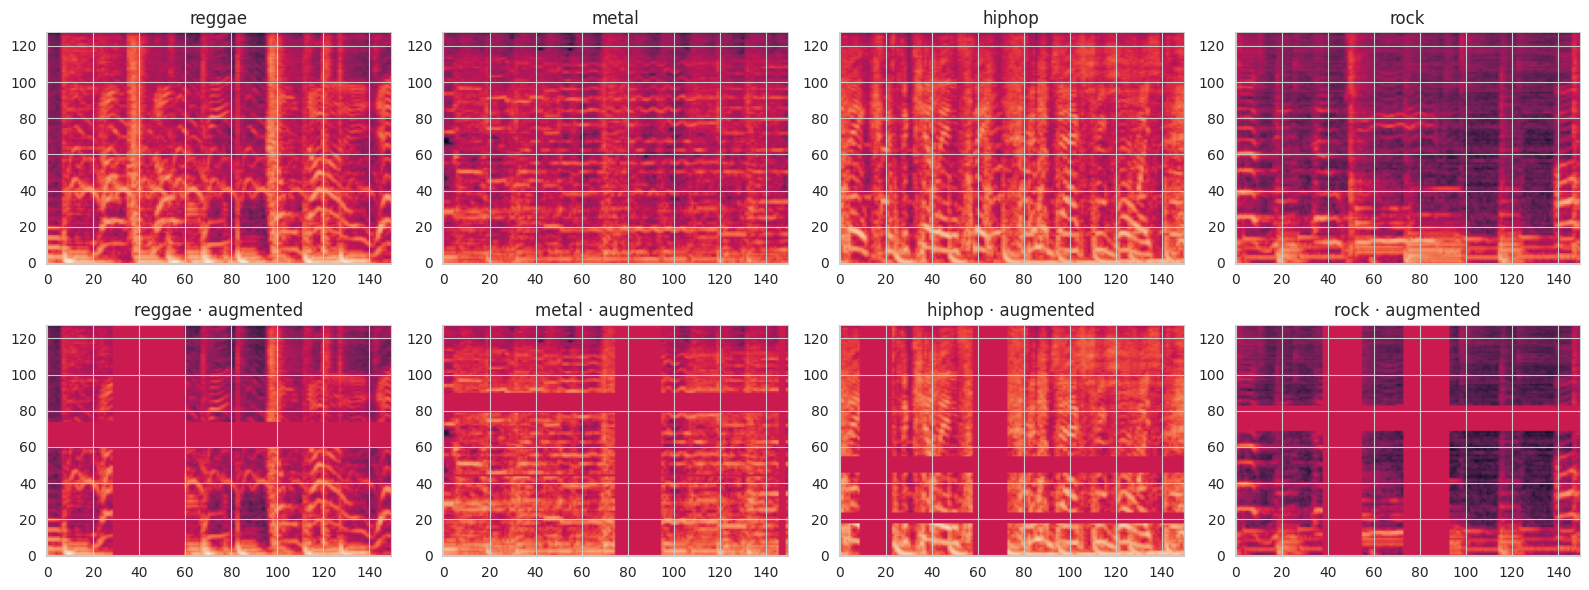

In [ ]:
Y_ALL     = torch.as_tensor(LABELS, device=DEVICE)
FRAME_IDX = torch.arange(CROP_FRAMES, device=DEVICE)

def sample_batch(songs_t, bs):
    """Random songs, random 3 s crop each -> x [B,1,mels,T], y [B]."""
    s  = songs_t[torch.randint(len(songs_t), (bs,), device=DEVICE)]
    st = torch.randint(0, N_FRAMES - CROP_FRAMES + 1, (bs,), device=DEVICE)
    x  = MEL_T[s[:, None], st[:, None] + FRAME_IDX[None, :]]      # [B, T, mels]
    return x.transpose(1, 2).unsqueeze(1), Y_ALL[s]

def spec_augment_batch(x, n_t=2, max_t=20, n_f=2, max_f=16):
    """Per-sample time/frequency masking. Masked value 0 == the training mean after normalisation."""
    B, _, M, T = x.shape
    ar_t = torch.arange(T, device=x.device)[None, :]
    ar_f = torch.arange(M, device=x.device)[None, :]
    for _ in range(n_t):
        w = torch.randint(0, max_t + 1, (B, 1), device=x.device)
        s = (torch.rand(B, 1, device=x.device) * (T - w)).long()
        x = x.masked_fill(((ar_t >= s) & (ar_t < s + w))[:, None, None, :], 0.0)
    for _ in range(n_f):
        w = torch.randint(0, max_f + 1, (B, 1), device=x.device)
        s = (torch.rand(B, 1, device=x.device) * (M - w)).long()
        x = x.masked_fill(((ar_f >= s) & (ar_f < s + w))[:, None, :, None], 0.0)
    return x

def augment(x, gain_db=6.0):
    x = x + (torch.randn(x.shape[0], 1, 1, 1, device=x.device) * gain_db) / STD    # gain jitter in dB
    return spec_augment_batch(x)

# sanity check: what the network actually sees (top = raw crop, bottom = augmented)
tr_t = torch.as_tensor(tr_idx, device=DEVICE)
x, y = sample_batch(tr_t, 4); xa = augment(x.clone())
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for k in range(4):
    for r, t in enumerate((x, xa)):
        ax[r, k].imshow(t[k, 0].cpu().numpy(), origin="lower", aspect="auto", vmin=-3, vmax=3)
        ax[r, k].set_title(id2label[int(y[k])] + (" · augmented" if r else ""))
plt.tight_layout(); plt.show()

In [ ]:
import copy

# ---------------- hyper-parameters (edit freely) ----------------
EPOCHS         = 80
BATCH          = 64
CROPS_PER_SONG = 6        # random crops per training song per epoch
LR             = 2e-3     # one-cycle peak
WD             = 0.05
BASE_CH        = 32
LABEL_SMOOTH   = 0.1
MIXUP_ALPHA    = 0.2
MIXUP_PROB     = 0.5
# -----------------------------------------------------------------

@torch.no_grad()
def song_probs(model, idx, hop=CROP_FRAMES // 2):
    """One probability vector per song: mean softmax over all overlapping 3 s windows."""
    model.eval()
    return torch.stack([model(mel_windows(MEL_T[i].T, hop)).float().softmax(-1).mean(0).cpu() for i in idx]).numpy()

def nll(P, y):
    return float(-np.log(P[np.arange(len(y)), y] + 1e-9).mean())

seed_everything(SEED)
use_amp = DEVICE == "cuda"
model   = GenreCNN(n_classes=len(GENRES), base_ch=BASE_CH, dropout=0.4).to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.2f} M parameters (random init - nothing pretrained)")

steps_per_epoch = max(1, len(tr_idx) * CROPS_PER_SONG // BATCH)
opt    = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
sched  = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch, pct_start=0.2)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
crit   = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

history, best = [], {"val_nll": 1e9, "epoch": 0, "state": None}
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train(); tot = torch.zeros((), device=DEVICE)
    for _ in range(steps_per_epoch):
        x, y = sample_batch(tr_t, BATCH)
        x = augment(x)
        use_mix = np.random.rand() < MIXUP_PROB
        if use_mix:
            lam  = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
            perm = torch.randperm(x.size(0), device=DEVICE)
            x = lam * x + (1 - lam) * x[perm]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            out  = model(x)
            loss = (lam * crit(out, y) + (1 - lam) * crit(out, y[perm])) if use_mix else crit(out, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.detach()

    pv = song_probs(model, va_idx)
    rec = dict(epoch=epoch, train_loss=float(tot) / steps_per_epoch,
               val_nll=nll(pv, LABELS[va_idx]), val_acc=accuracy_score(LABELS[va_idx], pv.argmax(1)))
    history.append(rec)
    if rec["val_nll"] < best["val_nll"]:
        best = dict(val_nll=rec["val_nll"], epoch=epoch, state=copy.deepcopy(model.state_dict()))
    if epoch % 5 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"epoch {epoch:3d}/{EPOCHS} | train loss {rec['train_loss']:.3f} | val NLL {rec['val_nll']:.3f} | "
              f"val song-acc {rec['val_acc']:.1%} | {time.time()-t0:.0f}s")

print(f"\nbest epoch by val loss: {best['epoch']} (val NLL {best['val_nll']:.3f})")

1.18 M parameters (random init - nothing pretrained)
epoch   1/80 | train loss 2.286 | val NLL 1.765 | val song-acc 42.0% | 8s
epoch   5/80 | train loss 1.842 | val NLL 1.369 | val song-acc 59.0% | 32s
epoch  10/80 | train loss 1.672 | val NLL 1.265 | val song-acc 62.0% | 62s
epoch  15/80 | train loss 1.496 | val NLL 1.041 | val song-acc 70.0% | 94s
epoch  20/80 | train loss 1.420 | val NLL 0.998 | val song-acc 68.0% | 125s
epoch  25/80 | train loss 1.306 | val NLL 0.853 | val song-acc 78.0% | 157s
epoch  30/80 | train loss 1.240 | val NLL 0.695 | val song-acc 83.0% | 189s
epoch  35/80 | train loss 1.166 | val NLL 0.799 | val song-acc 75.0% | 220s
epoch  40/80 | train loss 1.062 | val NLL 0.662 | val song-acc 82.0% | 252s
epoch  45/80 | train loss 1.060 | val NLL 0.599 | val song-acc 82.0% | 283s
epoch  50/80 | train loss 0.977 | val NLL 0.660 | val song-acc 81.0% | 314s
epoch  55/80 | train loss 0.948 | val NLL 0.594 | val song-acc 81.0% | 346s
epoch  60/80 | train loss 0.990 | val NL

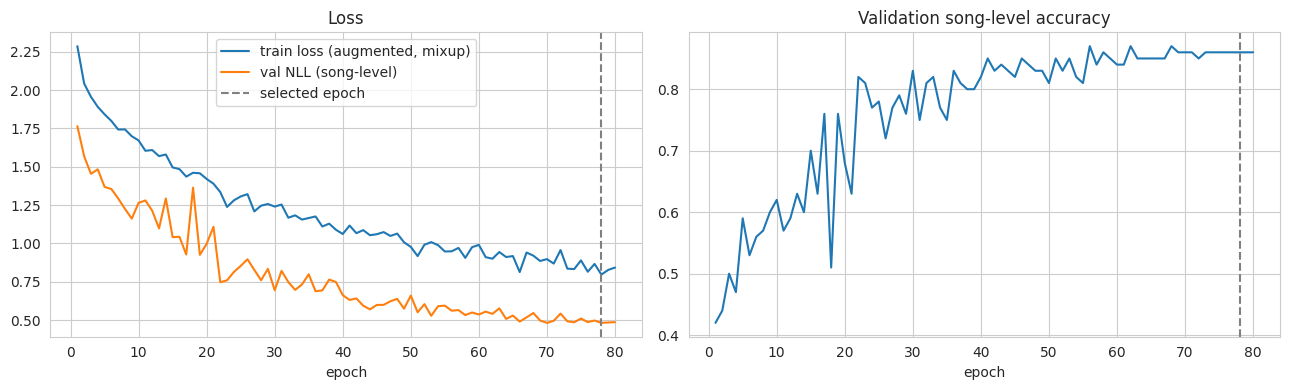

In [ ]:
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist.epoch, hist.train_loss, label="train loss (augmented, mixup)")
ax[0].plot(hist.epoch, hist.val_nll, label="val NLL (song-level)")
ax[0].axvline(best["epoch"], color="gray", ls="--", label="selected epoch"); ax[0].legend(); ax[0].set_xlabel("epoch"); ax[0].set_title("Loss")
ax[1].plot(hist.epoch, hist.val_acc); ax[1].axvline(best["epoch"], color="gray", ls="--")
ax[1].set_title("Validation song-level accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [ ]:
model.load_state_dict(best["state"]); model.eval()
P_val_cnn  = song_probs(model, va_idx)
P_test_cnn = song_probs(model, te_idx)

acc_cnn_val  = accuracy_score(LABELS[va_idx], P_val_cnn.argmax(1))
acc_cnn_test = accuracy_score(LABELS[te_idx], P_test_cnn.argmax(1))
print(f"CNN (from scratch)  val song-acc {acc_cnn_val:.1%} | test song-acc {acc_cnn_test:.1%}")

CNN (from scratch)  val song-acc 86.0% | test song-acc 91.0%


###comparison table, report and confusion matrix

,val_song_acc,test_song_acc
model,,
CNN (from scratch),86.0%,91.0%
SVM (RBF),81.0%,86.0%
Gradient Boosting,81.0%,81.0%
Random Forest,83.0%,77.0%
Extra Trees,79.0%,75.0%


              precision    recall  f1-score   support

       blues      1.000     0.900     0.947        10
   classical      1.000     1.000     1.000        10
     country      0.900     0.900     0.900        10
       disco      0.900     0.900     0.900        10
      hiphop      0.900     0.900     0.900        10
        jazz      1.000     1.000     1.000        10
       metal      0.900     0.900     0.900        10
         pop      0.750     0.900     0.818        10
      reggae      1.000     0.800     0.889        10
        rock      0.818     0.900     0.857        10

    accuracy                          0.910       100
   macro avg      0.917     0.910     0.911       100
weighted avg      0.917     0.910     0.911       100



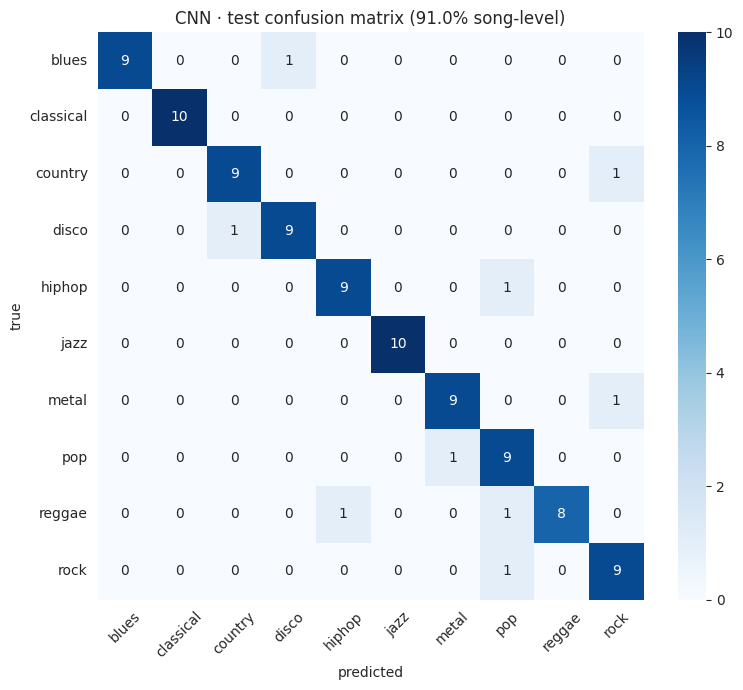

In [ ]:
summary = classical_df[["val_song_acc", "test_song_acc"]].copy()
summary.loc["CNN (from scratch)"] = [acc_cnn_val, acc_cnn_test]
display(summary.sort_values("test_song_acc", ascending=False).style.format("{:.1%}"))

y_true = LABELS[te_idx]; y_pred = P_test_cnn.argmax(1)
print(classification_report(y_true, y_pred, target_names=GENRES, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=GENRES, yticklabels=GENRES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"CNN · test confusion matrix ({acc_cnn_test:.1%} song-level)")
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=150); plt.show()

In [ ]:
P_val_clf, P_test_clf = clf_probs[BEST_CLF_NAME]

best_w, best_va = 1.0, -1.0
for w in np.linspace(1, 0, 21):                     # ties favour the CNN
    acc = accuracy_score(LABELS[va_idx], (w * P_val_cnn + (1 - w) * P_val_clf).argmax(1))
    if acc > best_va + 1e-9:
        best_w, best_va = w, acc

acc_ens_test = accuracy_score(LABELS[te_idx], (best_w * P_test_cnn + (1 - best_w) * P_test_clf).argmax(1))
print(f"ensemble weight on CNN = {best_w:.2f} (+{BEST_CLF_NAME}) | val {best_va:.1%} | test {acc_ens_test:.1%}")
print("Note: with only 100 val songs, treat any ensemble gain as tentative.")

ensemble weight on CNN = 0.55 (+Random Forest) | val 88.0% | test 92.0%
Note: with only 100 val songs, treat any ensemble gain as tentative.


In [ ]:
import joblib

# 1) CNN weights + config (PyTorchModelHubMixin -> model.safetensors + config.json)
model.cpu().save_pretrained(SAVE_DIR)
model.to(DEVICE)

# 2) the exact model + preprocessing source that was trained, so anyone can load it
open(f"{SAVE_DIR}/genre_cnn.py", "w").write(MODEL_SRC)
json.dump({"mean": MEAN, "std": STD, "sr": SR, "labels": id2label}, open(f"{SAVE_DIR}/preprocess.json", "w"), indent=2)

# 3) Random Forest baseline in a sub-folder
os.makedirs(f"{SAVE_DIR}/classical", exist_ok=True)
joblib.dump({"model": clf_zoo["Random Forest"], "feature_names": FEATURE_NAMES, "labels": GENRES,
             "sr": SR, "segment_seconds": 3, "note": "average predict_proba over 10 x 3 s segments"},
            f"{SAVE_DIR}/classical/random_forest.joblib", compress=3)

# 4) metrics
rf_test = float(classical_df.loc["Random Forest", "test_song_acc"])
METRICS = {"cnn_val_song_acc": acc_cnn_val, "cnn_test_song_acc": acc_cnn_test, "cnn_best_epoch": best["epoch"],
           "random_forest_test_song_acc": rf_test, "ensemble_test_song_acc": acc_ens_test,
           "ensemble_weight_cnn": best_w, "n_train_songs": int(len(tr_idx)),
           "n_val_songs": int(len(va_idx)), "n_test_songs": int(len(te_idx))}
json.dump(METRICS, open(f"{SAVE_DIR}/metrics.json", "w"), indent=2)

# 5) model card
card = f"""---
license: mit
library_name: pytorch
pipeline_tag: audio-classification
tags:
- audio
- audio-classification
- music
- genre-classification
- gtzan
- cnn
- from-scratch
metrics:
- accuracy
---

# GTZAN music genre CNN (trained from scratch)

A small convolutional network (~1.2 M parameters, **random initialisation, no pretrained weights**) trained on
log-mel spectrograms of GTZAN. Genres: {", ".join(GENRES)}.

## Results (leak-free, song-level split)

Split by **song**: {len(tr_idx)} train / {len(va_idx)} val / {len(te_idx)} test. Each test song is scored by averaging
predictions over all overlapping 3-second windows.

| Model | Test accuracy |
|---|---|
| **CNN (this model)** | **{acc_cnn_test:.1%}** |
| Random Forest on hand-crafted features (`classical/random_forest.joblib`) | {rf_test:.1%} |
| CNN + {BEST_CLF_NAME} soft-vote ensemble | {acc_ens_test:.1%} |

Validation accuracy: {acc_cnn_val:.1%} (selected epoch {best["epoch"]}, chosen by validation loss).
The test set has only {len(te_idx)} songs, so expect several points of noise.

## Usage

```python
import importlib.util, json, librosa
from huggingface_hub import hf_hub_download

repo = "YOUR_USERNAME/{HF_REPO_NAME}"
spec = importlib.util.spec_from_file_location("genre_cnn", hf_hub_download(repo, "genre_cnn.py"))
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)

model = mod.GenreCNN.from_pretrained(repo).eval()
pre = json.load(open(hf_hub_download(repo, "preprocess.json")))

y, _ = librosa.load("song.mp3", sr=16000, mono=True)
probs = mod.predict_song(model, y, pre["mean"], pre["std"])
print(pre["labels"][str(int(probs.argmax()))])
```

## Training recipe
Random 3 s crops, gain jitter, SpecAugment masks, mixup (alpha {MIXUP_ALPHA}, p={MIXUP_PROB}), AdamW (peak lr {LR}, wd {WD}),
one-cycle schedule, label smoothing {LABEL_SMOOTH}, {EPOCHS} epochs x {CROPS_PER_SONG} crops per song.

## Limitations
GTZAN is small (1,000 clips), has known label noise, duplicates and artist overlap, and covers only 10 Western genres.
These numbers will not transfer to arbitrary real-world music.
"""
open(f"{SAVE_DIR}/README.md", "w").write(card)
print(sorted(os.listdir(SAVE_DIR)))

['README.md', 'classical', 'config.json', 'confusion_matrix.png', 'genre_cnn.py', 'metrics.json', 'model.safetensors', 'preprocess.json']


In [ ]:

from huggingface_hub import HfApi, login
from getpass import getpass

# 1. Take HF token as input (hidden)
HF_TOKEN = getpass("Enter your Hugging Face token: ")

# 2. Authenticate
login(token=HF_TOKEN)

# 3. Initialize API
api = HfApi(token=HF_TOKEN)

# 4. Get username and construct repository ID
user = api.whoami()["name"]
REPO_ID = f"{user}/{HF_REPO_NAME}"

# 5. Create repository (if it doesn't exist)
api.create_repo(
    repo_id=REPO_ID,
    repo_type="model",
    exist_ok=True,
    private=PRIVATE_REPO
)

# 6. Upload model and all files inside SAVE_DIR
api.upload_folder(
    folder_path=SAVE_DIR,
    repo_id=REPO_ID,
    repo_type="model",
    commit_message=f"From-scratch CNN on GTZAN - test song-acc {acc_cnn_test:.1%}"
)

print(f"\nModel is live: https://huggingface.co/{REPO_ID}")


Enter your Hugging Face token: ··········

Model is live: https://huggingface.co/anmolsehgal/gtzan-genre-cnn


In [ ]:
import importlib.util
from huggingface_hub import hf_hub_download

spec = importlib.util.spec_from_file_location("genre_cnn_hub", hf_hub_download(REPO_ID, "genre_cnn.py"))
hub_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(hub_mod)
hub_model = hub_mod.GenreCNN.from_pretrained(REPO_ID).to(DEVICE).eval()
pre = json.load(open(hf_hub_download(REPO_ID, "preprocess.json")))

def classify(wave, top_k=3):
    p = hub_mod.predict_song(hub_model, wave, pre["mean"], pre["std"])
    order = p.argsort()[::-1][:top_k]
    return [(id2label[int(i)], float(p[i])) for i in order], p

i = int(te_idx[0])
top, p = classify(WAVES[i])
print("true genre:", meta.genre[i], "|", meta.song[i])
for g, pr in top:
    print(f"  {g:10s} {pr:6.1%}")
print("\nmax |prob difference| vs the in-notebook model:", float(np.abs(p - P_test_cnn[0]).max()), "(should be ~0)")

genre_cnn.py:   0%|          | 0.00/2.77k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/56.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.72MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocess.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

true genre: metal | metal.00053
  metal       97.2%
  country      0.7%
  jazz         0.4%

max |prob difference| vs the in-notebook model: 6.984919309616089e-10 (should be ~0)
